In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Import the data
* Import data that describe countries in one point

In [3]:
one_point_countries = pd.read_parquet('../data/one_point_countries.parquet')

In [4]:
one_point_countries.head()

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_cv,labor_force_min,labor_force_max,labor_force_last,labor_force_growth,labor_force_skew,...,govermment_effective__std,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend,iso_a3
0,Australia,13.582,13.585,0.618398,0.045531,12.73,14.50,14.50,0.139042,0.097090,...,0.036180,2.347833e-02,1.47,1.59,1.59,0.039216,-0.346877,-0.627720,0.005273,AUS
1,Austria,4.679,4.650,0.092569,0.019784,4.57,4.83,4.83,0.056893,0.530756,...,0.078968,5.401392e-02,1.33,1.61,1.33,-0.095238,-0.207178,-0.148237,-0.011879,AUT
2,Belgium,5.205,5.180,0.151013,0.029013,5.00,5.42,5.42,0.084000,0.146086,...,0.129016,1.088738e-01,1.04,1.40,1.04,-0.257143,0.542175,-1.048411,-0.037758,BEL
3,Brazil,103.729,103.950,2.291325,0.022090,99.69,106.30,106.10,0.048419,-0.373023,...,0.135632,-3.214025e-01,-0.59,-0.23,-0.55,1.200000,0.321185,-1.620024,-0.038182,BRA
4,Bulgaria,3.255,3.270,0.095525,0.029347,3.09,3.38,3.09,-0.055046,-0.624667,...,0.146969,-5.295130e+16,-0.27,0.17,0.05,-0.444444,-0.794950,-1.012397,-0.022303,BGR


### Search outliers
* Look for outliers
* Plot boxplot for every feature

In [5]:
def detect_outliers_in_dataframe(df, iqr_multiplier=1.5):
    outlier_report = {}

    # Excluye columnas no numéricas
    numeric_cols = df.select_dtypes(include=[np.number]).columns

    for idx, row in df.iterrows():
        country_name = row["Country"]
        outlier_cols = []

        for col in numeric_cols:
            value = row[col]
            col_series = df[col].dropna()

            # Calcula los límites usando IQR
            q1 = np.percentile(col_series, 25)
            q3 = np.percentile(col_series, 75)
            iqr = q3 - q1
            lower_bound = q1 - iqr_multiplier * iqr
            upper_bound = q3 + iqr_multiplier * iqr

            if value < lower_bound or value > upper_bound:
                outlier_cols.append(col)

        outlier_report[country_name] = outlier_cols

    return outlier_report


In [6]:
outliers = detect_outliers_in_dataframe(one_point_countries)
for country, cols in outliers.items():
    print(f"{country}: {cols}")

Australia: ['livestock_prod_min', 'cpi_min']
Austria: ['share_of_industry__kurtosis']
Belgium: ['agr_land_skew', 'agr_land_kurtosis', 'edu_spending__kurtosis']
Brazil: ['labor_force_mean', 'labor_force_median', 'labor_force_std', 'labor_force_min', 'labor_force_max', 'labor_force_last', 'labor_force_trend', 'cpi_mean', 'cpi_median', 'cpi_std', 'cpi_min', 'cpi_max', 'cpi_last', 'cpi_skew', 'cpi_trend', 'rule_of_law__cv', 'share_of_industry__cv', 'share_of_industry__growth', 'govermment_effective__cv', 'govermment_effective__growth']
Bulgaria: ['livestock_prod_min', 'rule_of_law__cv', 'rule_of_law__growth', 'govermment_effective__cv']
Canada: ['cpi_mean', 'cpi_median', 'cpi_min', 'unemployment_kurtosis']
Chile: ['agr_land_cv', 'agr_land_growth', 'agr_land_trend', 'gov_exp_mean', 'gov_exp_median', 'gov_exp_std', 'gov_exp_min', 'gov_exp_max', 'gov_exp_last', 'gov_exp_trend', 'investment_mean', 'investment_median', 'investment_std', 'investment_min', 'investment_max', 'investment_last', 'in

In [7]:
def outlier_dict_to_df(outlier_dict):
    data = [{"Country": country, "Outlier_Count": len(cols)} for country, cols in outlier_dict.items()]
    return pd.DataFrame(data)

In [12]:
def apply_pareto_rule_to_outliers(outlier_df, threshold=0.8):
    """
    Applies the Pareto 80/20 rule to identify the smallest set of countries
    responsible for at least 'threshold' proportion of total outliers.

    Parameters:
    - outlier_df: DataFrame with columns 'Country' and 'Outlier_Count'
    - threshold: float, default 0.8 (80%)

    Returns:
    - DataFrame of top countries contributing to the majority of outliers
    """

    sorted_df = outlier_df.sort_values(by="Outlier_Count", ascending=False).reset_index(drop=True)
    total_outliers = sorted_df["Outlier_Count"].sum()

    sorted_df["Cumulative_Outliers"] = sorted_df["Outlier_Count"].cumsum()
    sorted_df["Cumulative_%"] = sorted_df["Cumulative_Outliers"] / total_outliers

    pareto_df = sorted_df[sorted_df["Cumulative_%"] <= threshold].copy()

    if not pareto_df.empty and pareto_df["Cumulative_%"].iloc[-1] < threshold:
        next_row = sorted_df.iloc[len(pareto_df)]
        pareto_df = pd.concat([pareto_df, next_row.to_frame().T], ignore_index=True)

    # Fix: Ensure numeric before rounding
    pareto_df["Cumulative_%"] = pd.to_numeric(pareto_df["Cumulative_%"], errors="coerce") * 100
    pareto_df["Cumulative_%"] = pareto_df["Cumulative_%"].round(2)

    return pareto_df

In [13]:
# Paso 2: convertir a DataFrame
outlier_df = outlier_dict_to_df(outliers)

# Paso 3: aplicar regla de Pareto
pareto_df = apply_pareto_rule_to_outliers(outlier_df, threshold=0.8)

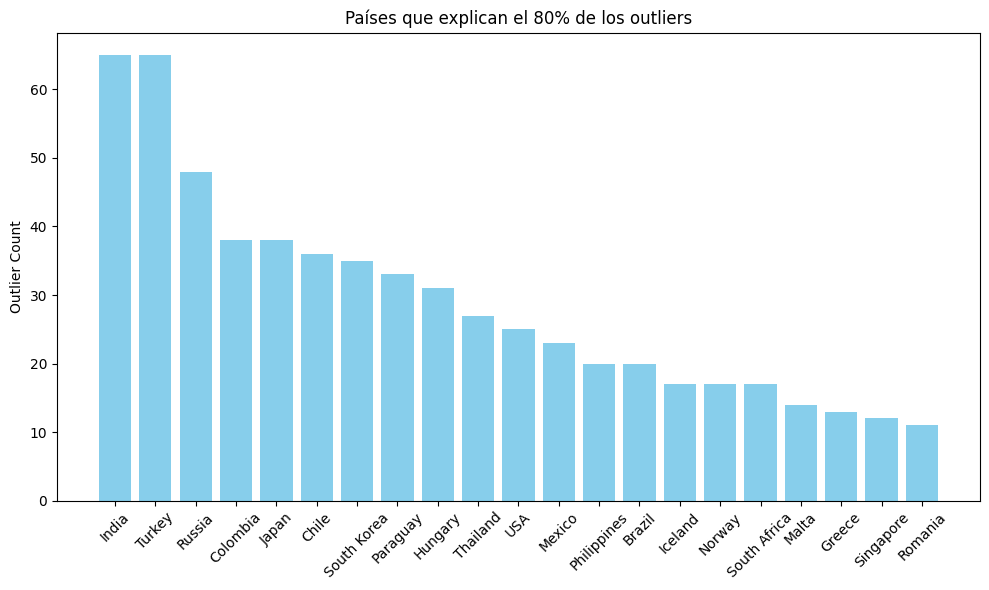

In [14]:
plt.figure(figsize=(10, 6))
plt.bar(pareto_df["Country"], pareto_df["Outlier_Count"], color="skyblue")
plt.xticks(rotation=45)
plt.ylabel("Outlier Count")
plt.title("Países que explican el 80% de los outliers")
plt.tight_layout()
plt.show()

In [15]:
pareto_df

,Country,Outlier_Count,Cumulative_Outliers,Cumulative_%
0,India,65,65,8.74
1,Turkey,65,130,17.47
2,Russia,48,178,23.92
3,Colombia,38,216,29.03
4,Japan,38,254,34.14
5,Chile,36,290,38.98
6,South Korea,35,325,43.68
7,Paraguay,33,358,48.12
8,Hungary,31,389,52.28
9,Thailand,27,416,55.91


In [18]:
from collections import Counter

In [19]:
def rank_outlier_variables(outlier_dict, exclude_columns={"Year"}):
    counter = Counter()
    for macro_list in outlier_dict.values():
        filtered_macros = [col for col in macro_list if col not in exclude_columns]
        counter.update(filtered_macros)

    sorted_macros = sorted(counter.items(), key=lambda x: x[1], reverse=True)

    print("📊 Ranking de macroeconómicos con outliers (por número de países):\n")
    for macro, count in sorted_macros:
        print(f"{macro}: {count} países")

In [20]:
rank_outlier_variables(outliers)

📊 Ranking de macroeconómicos con outliers (por número de países):

cpi_min: 17 países
govermment_effective__cv: 16 países
rule_of_law__cv: 13 países
cpi_median: 12 países
investment_median: 12 países
investment_min: 12 países
gdp_median: 12 países
gdp_min: 12 países
investment_mean: 11 países
investment_std: 11 países
investment_max: 11 países
investment_last: 11 países
gdp_max: 11 países
gdp_last: 11 países
gov_exp_std: 10 países
gov_exp_trend: 10 países
investment_trend: 10 países
gdp_mean: 10 países
gdp_std: 10 países
gdp_trend: 10 países
cpi_mean: 9 países
govermment_effective__growth: 9 países
gov_exp_mean: 9 países
gov_exp_median: 9 países
gov_exp_min: 9 países
gov_exp_max: 9 países
gov_exp_last: 9 países
priv_cred_mean: 9 países
priv_cred_median: 9 países
priv_cred_std: 9 países
priv_cred_min: 9 países
priv_cred_max: 9 países
priv_cred_last: 9 países
priv_cred_trend: 9 países
urban_pop_kurtosis: 9 países
labor_force_trend: 8 países
agr_land_growth: 8 países
inflation__growth: 8 

In [21]:
def apply_pareto_to_variables(outlier_dict, threshold=0.8, exclude_columns={"Year"}):
    from collections import Counter
    import pandas as pd

    # Contar ocurrencias de cada variable como outlier
    counter = Counter()
    for macro_list in outlier_dict.values():
        filtered_macros = [col for col in macro_list if col not in exclude_columns]
        counter.update(filtered_macros)

    # Convertir a DataFrame
    df = pd.DataFrame(counter.items(), columns=["Variable", "Outlier_Count"])
    df = df.sort_values(by="Outlier_Count", ascending=False).reset_index(drop=True)

    # Aplicar regla de Pareto
    total_outliers = df["Outlier_Count"].sum()
    df["Cumulative_Outliers"] = df["Outlier_Count"].cumsum()
    df["Cumulative_%"] = df["Cumulative_Outliers"] / total_outliers

    pareto_df = df[df["Cumulative_%"] <= threshold].copy()

    if not pareto_df.empty and pareto_df["Cumulative_%"].iloc[-1] < threshold:
        next_row = df.iloc[len(pareto_df)]
        pareto_df = pd.concat([pareto_df, next_row.to_frame().T], ignore_index=True)

    pareto_df["Cumulative_%"] = pd.to_numeric(pareto_df["Cumulative_%"], errors="coerce") * 100
    pareto_df["Cumulative_%"] = pareto_df["Cumulative_%"].round(2)

    return pareto_df

In [22]:
pareto_variables_df = apply_pareto_to_variables(outliers)

In [24]:
pareto_variables_df

,Variable,Outlier_Count,Cumulative_Outliers,Cumulative_%
0,cpi_min,17,17,2.28
1,govermment_effective__cv,16,33,4.44
2,rule_of_law__cv,13,46,6.18
3,cpi_median,12,58,7.80
4,investment_min,12,70,9.41
...,...,...,...,...
75,priv_cred_growth,4,583,78.36
76,gov_exp_skew,4,587,78.90
77,reserves_median,4,591,79.44
78,agr_land_skew,3,594,79.84


In [25]:
def pareto_variables_with_countries(outlier_dict, threshold=0.8, exclude_columns={"Year"}):
    from collections import Counter, defaultdict
    import pandas as pd

    # Paso 1: contar ocurrencias por variable
    counter = Counter()
    variable_to_countries = defaultdict(list)

    for country, macro_list in outlier_dict.items():
        for var in macro_list:
            if var not in exclude_columns:
                counter[var] += 1
                variable_to_countries[var].append(country)

    # Paso 2: crear DataFrame ordenado por frecuencia
    df = pd.DataFrame(counter.items(), columns=["Variable", "Outlier_Count"])
    df = df.sort_values(by="Outlier_Count", ascending=False).reset_index(drop=True)

    # Paso 3: aplicar regla de Pareto
    total_outliers = df["Outlier_Count"].sum()
    df["Cumulative_Outliers"] = df["Outlier_Count"].cumsum()
    df["Cumulative_%"] = df["Cumulative_Outliers"] / total_outliers

    pareto_df = df[df["Cumulative_%"] <= threshold].copy()

    if not pareto_df.empty and pareto_df["Cumulative_%"].iloc[-1] < threshold:
        next_row = df.iloc[len(pareto_df)]
        pareto_df = pd.concat([pareto_df, next_row.to_frame().T], ignore_index=True)

    pareto_df["Cumulative_%"] = pd.to_numeric(pareto_df["Cumulative_%"], errors="coerce") * 100
    pareto_df["Cumulative_%"] = pareto_df["Cumulative_%"].round(2)

    # Paso 4: agregar países responsables
    pareto_df["Countries"] = pareto_df["Variable"].apply(lambda var: variable_to_countries[var])

    return pareto_df

In [26]:
pareto_result = pareto_variables_with_countries(outliers, threshold=0.8)

In [27]:
pareto_result

,Variable,Outlier_Count,Cumulative_Outliers,Cumulative_%,Countries
0,cpi_min,17,17,2.28,"[Australia, Brazil, Canada, Chile, Colombia, I..."
1,govermment_effective__cv,16,33,4.44,"[Brazil, Bulgaria, Colombia, Greece, India, Me..."
2,rule_of_law__cv,13,46,6.18,"[Brazil, Bulgaria, Colombia, Greece, India, Me..."
3,cpi_median,12,58,7.80,"[Brazil, Canada, Chile, India, Israel, Malaysi..."
4,investment_min,12,70,9.41,"[Chile, Colombia, Hungary, India, Japan, Mexic..."
...,...,...,...,...,...
75,priv_cred_growth,4,583,78.36,"[Cyprus, India, Philippines, Turkey]"
76,gov_exp_skew,4,587,78.90,"[Croatia, Israel, Thailand, Turkey]"
77,reserves_median,4,591,79.44,"[Czech, India, Japan, Thailand]"
78,agr_land_skew,3,594,79.84,"[Belgium, Estonia, Malaysia]"


In [28]:
def extract_unique_countries(pareto_df, column_name="Countries"):
    all_countries = []

    for country_list in pareto_df[column_name]:
        all_countries.extend(country_list)

    unique_countries = sorted(set(all_countries))
    return unique_countries

In [29]:
unique_countries = extract_unique_countries(pareto_result)

In [30]:
unique_countries

['Australia',
 'Belgium',
 'Brazil',
 'Bulgaria',
 'Canada',
 'Chile',
 'Colombia',
 'Croatia',
 'Cyprus',
 'Czech',
 'Denmark',
 'Estonia',
 'France',
 'Germany',
 'Greece',
 'Hungary',
 'Iceland',
 'India',
 'Ireland',
 'Israel',
 'Japan',
 'Latvia',
 'Lithuania',
 'Luxembourg',
 'Malaysia',
 'Malta',
 'Mexico',
 'Netherlands',
 'New Zealand',
 'Norway',
 'Paraguay',
 'Peru',
 'Philippines',
 'Poland',
 'Portugal',
 'Romania',
 'Russia',
 'Serbia',
 'Singapore',
 'Slovakia',
 'Slovenia',
 'South Africa',
 'South Korea',
 'Spain',
 'Sweden',
 'Switzerland',
 'Thailand',
 'Turkey',
 'USA']

In [31]:
len(unique_countries)

49

* Make no sense, we have 53 countries and with this idea we want to eliminate 49
* So apply winsorization, robust scaler and log transformation one time and see the countries that are responsables for the 80% of the remaining outliers

### Apply transformations
* Apply log transformation to selected features
* Apply standard scaler to others
* Plot again the box plot for every feature to see for outliers
* If necessary winsorize features that remains with outliers

In [32]:
def adaptive_log_transform(df):
    """
    Applies logarithmic transformation to numeric columns with outliers,
    choosing between log(x) and log1p(x) based on the presence of near-zero values.

    Parameters:
    ----------
    df : pandas.DataFrame
        The input DataFrame containing numeric and non-numeric columns.

    Returns:
    -------
    transformed_df : pandas.DataFrame
        A copy of the original DataFrame with selected numeric columns log-transformed.
        Columns are transformed only if:
            - They contain outliers (based on IQR method).
            - All values are strictly positive.
            - If values are close to zero, log1p(x) is used instead of log(x).
    """

    numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns
    transformed_df = df.copy()

    for col in numeric_cols:
        series = df[col]

        # Check for outliers using IQR
        Q1 = series.quantile(0.25)
        Q3 = series.quantile(0.75)
        IQR = Q3 - Q1
        outliers = series[(series < Q1 - 1.5 * IQR) | (series > Q3 + 1.5 * IQR)]

        # Proceed only if outliers exist and all values are positive
        if outliers.shape[0] > 0 and (series > 0).all():
            min_val = series.min()

            # Use log1p if values are close to zero
            if min_val < 1:
                transformed_df[col] = np.log1p(series)
                print(f"Applied log1p transformation to column: {col}")
            else:
                transformed_df[col] = np.log(series)
                print(f"Applied log transformation to column: {col}")

    return transformed_df

In [33]:
df_log_transf = adaptive_log_transform(one_point_countries)

Applied log1p transformation to column: labor_force_mean
Applied log1p transformation to column: labor_force_median
Applied log1p transformation to column: labor_force_std
Applied log1p transformation to column: labor_force_min
Applied log1p transformation to column: labor_force_max
Applied log1p transformation to column: labor_force_last
Applied log transformation to column: livestock_prod_mean
Applied log transformation to column: livestock_prod_median
Applied log1p transformation to column: livestock_prod_std
Applied log1p transformation to column: livestock_prod_cv
Applied log transformation to column: livestock_prod_min
Applied log transformation to column: livestock_prod_max
Applied log transformation to column: livestock_prod_last
Applied log transformation to column: urban_pop_mean
Applied log transformation to column: urban_pop_median
Applied log transformation to column: urban_pop_min
Applied log transformation to column: urban_pop_max
Applied log transformation to column: ur

In [34]:
from sklearn.preprocessing import RobustScaler

In [35]:
def apply_robust_scaler(original_df, log_transformed_df):
    """
    Applies RobustScaler to numeric columns that were not log-transformed.

    Parameters:
    ----------
    original_df : pandas.DataFrame
        The original DataFrame before any transformations.

    log_transformed_df : pandas.DataFrame
        The DataFrame after applying log transformations to selected columns.

    Returns:
    -------
    scaled_df : pandas.DataFrame
        A copy of the log_transformed_df with RobustScaler applied to numeric columns
        that were not previously log-transformed.
    """

    # Identify numeric columns in both DataFrames
    original_numeric = original_df.select_dtypes(include=['float64', 'int64']).columns
    transformed_numeric = log_transformed_df.select_dtypes(include=['float64', 'int64']).columns

    # Columns that were not transformed (same values as original)
    untouched_columns = [
        col for col in original_numeric
        if col in transformed_numeric and original_df[col].equals(log_transformed_df[col])
    ]

    # Apply RobustScaler to untouched numeric columns
    scaler = RobustScaler()
    scaled_df = log_transformed_df.copy()
    scaled_df[untouched_columns] = scaler.fit_transform(original_df[untouched_columns])

    print(f"Applied RobustScaler to columns: {untouched_columns}")
    return scaled_df, untouched_columns


In [36]:
df_scaled, untouched_colums = apply_robust_scaler(one_point_countries, df_log_transf)

Applied RobustScaler to columns: ['labor_force_cv', 'labor_force_growth', 'labor_force_skew', 'labor_force_kurtosis', 'labor_force_trend', 'livestock_prod_growth', 'livestock_prod_skew', 'livestock_prod_kurtosis', 'livestock_prod_trend', 'agr_land_mean', 'agr_land_median', 'agr_land_std', 'agr_land_cv', 'agr_land_min', 'agr_land_max', 'agr_land_last', 'agr_land_growth', 'agr_land_skew', 'agr_land_kurtosis', 'agr_land_trend', 'urban_pop_std', 'urban_pop_cv', 'urban_pop_growth', 'urban_pop_skew', 'urban_pop_kurtosis', 'urban_pop_trend', 'gov_exp_skew', 'gov_exp_kurtosis', 'reserves_growth', 'reserves_skew', 'reserves_kurtosis', 'reserves_trend', 'investment_skew', 'investment_kurtosis', 'cpi_growth', 'cpi_skew', 'cpi_kurtosis', 'cpi_trend', 'gdp_skew', 'gdp_kurtosis', 'priv_cred_growth', 'priv_cred_skew', 'priv_cred_kurtosis', 'priv_cred_trend', 'unemployment_cv', 'unemployment_growth', 'unemployment_skew', 'unemployment_kurtosis', 'unemployment_trend', 'rule_of_law__mean', 'rule_of_law_

In [37]:
df_final = pd.concat([df_log_transf.drop(columns=untouched_colums), df_scaled[untouched_colums]], axis=1)
df_final.head()

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_min,labor_force_max,labor_force_last,livestock_prod_mean,livestock_prod_median,livestock_prod_std,...,govermment_effective__mean,govermment_effective__median,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend
0,Australia,2.679788,2.679994,0.481437,2.619583,2.740840,2.740840,4.528397,4.508659,1.820075,...,0.432566,0.422131,-4.897231e-01,0.470588,0.438596,0.444444,0.225607,-0.482700,1.086080,0.386612
1,Austria,1.736775,1.731656,0.088532,1.717395,1.763017,1.763017,4.614130,4.615121,0.377242,...,0.367599,0.368852,-1.871437e-01,0.352941,0.456140,0.251852,-0.098598,-0.237756,1.945877,0.000000
2,Belgium,1.825355,1.821318,0.140643,1.791759,1.859418,1.859418,4.636378,4.628887,0.985339,...,0.139803,0.118852,3.564674e-01,0.109244,0.271930,0.037037,-0.488994,1.076138,0.331708,-0.583333
3,Brazil,4.651376,4.653484,1.191290,4.612046,4.675629,4.673763,4.672829,4.675629,1.646041,...,-1.181743,-1.229508,-3.907173e+00,-1.260504,-1.157895,-1.140741,3.024576,0.688661,-0.693295,-0.592896
4,Bulgaria,1.448095,1.451614,0.091234,1.408545,1.477049,1.408545,4.527641,4.503691,1.688591,...,-0.834704,-0.778689,-5.246984e+17,-0.991597,-0.807018,-0.696296,-0.940630,-1.268340,0.396286,-0.234973


In [38]:
from scipy.stats.mstats import winsorize

In [39]:
def winsorize_outlier_columns(df, limits=(0.05, 0.05)):
    """
    Applies winsorization only to numeric columns that contain outliers (based on IQR).

    Parameters:
    - df: pandas DataFrame
    - limits: tuple (lower_limit, upper_limit) for winsorization percentiles

    Returns:
    - df_winsorized: DataFrame with selected columns winsorized
    - outlier_columns: list of columns that were winsorized
    """
    df_winsorized = df.copy()
    numeric_cols = df.select_dtypes(include='number').columns
    outlier_columns = []

    for col in numeric_cols:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        outliers = df[(df[col] < Q1 - 1.5 * IQR) | (df[col] > Q3 + 1.5 * IQR)]

        if not outliers.empty:
            arr = df[col].values
            arr_winsorized = winsorize(arr, limits=limits).data  # Convert to regular array
            df_winsorized[col] = arr_winsorized
            outlier_columns.append(col)

    return df_winsorized, outlier_columns

In [41]:
df_final_win, outliers_columns = winsorize_outlier_columns(df_final, limits=(0.10,0.10))

In [43]:
outliers_after_win = detect_outliers_in_dataframe(df_final_win)

In [44]:
pareto_after_win = pareto_variables_with_countries(outliers_after_win, threshold=0.8)

In [45]:
pareto_after_win

,Variable,Outlier_Count,Cumulative_Outliers,Cumulative_%,Countries
0,cpi_min,17,17,14.05,"[Australia, Brazil, Canada, Chile, Colombia, I..."
1,govermment_effective__cv,16,33,27.27,"[Brazil, Bulgaria, Colombia, Greece, India, Me..."
2,rule_of_law__cv,10,43,35.54,"[Brazil, Bulgaria, Colombia, Mexico, Paraguay,..."
3,priv_cred_trend,9,52,42.98,"[Chile, Colombia, Hungary, India, Japan, Parag..."
4,cpi_median,8,60,49.59,"[Brazil, Canada, India, New Zealand, Philippin..."
5,urban_pop_kurtosis,8,68,56.20,"[Cyprus, Denmark, Romania, Singapore, Slovakia..."
6,inflation__growth,8,76,62.81,"[Cyprus, Iceland, Ireland, Israel, Japan, Roma..."
7,govermment_effective__growth,7,83,68.60,"[Brazil, India, Mexico, Peru, Philippines, Rus..."
8,livestock_prod_min,7,90,74.38,"[Australia, Bulgaria, Colombia, Malta, Philipp..."
9,cpi_mean,7,97,80.17,"[Brazil, Canada, India, New Zealand, Russia, T..."


In [46]:
unique_countries_after_win = extract_unique_countries(pareto_after_win)

In [47]:
unique_countries_after_win

['Australia',
 'Brazil',
 'Bulgaria',
 'Canada',
 'Chile',
 'Colombia',
 'Cyprus',
 'Denmark',
 'Greece',
 'Hungary',
 'Iceland',
 'India',
 'Ireland',
 'Israel',
 'Japan',
 'Malaysia',
 'Malta',
 'Mexico',
 'New Zealand',
 'Paraguay',
 'Peru',
 'Philippines',
 'Poland',
 'Romania',
 'Russia',
 'Serbia',
 'Singapore',
 'Slovakia',
 'South Africa',
 'South Korea',
 'Switzerland',
 'Turkey',
 'USA']

In [51]:
len(unique_countries_after_win)

33

In [49]:
def remove_selected_countries_except(df, country_list, keep_country="Paraguay", column_name="Country"):
    """
    Elimina del DataFrame todos los países en 'country_list' excepto el país especificado en 'keep_country'.

    Parámetros:
    - df: pandas.DataFrame
        El DataFrame original que contiene la columna de países.
    - country_list: list
        Lista de países que se desean eliminar (excepto uno).
    - keep_country: str
        País que se desea conservar aunque esté en la lista.
    - column_name: str
        Nombre de la columna que contiene los nombres de países.

    Retorna:
    - df_filtrado: pandas.DataFrame
        DataFrame con los países eliminados según la lógica.
    """

    # Crear nueva lista excluyendo el país que queremos conservar
    countries_to_remove = [c for c in country_list if c != keep_country]

    # Filtrar el DataFrame
    df_filtrado = df[~df[column_name].isin(countries_to_remove)].copy()

    print(f"Se eliminaron {len(countries_to_remove)} países, excepto '{keep_country}'.")
    return df_filtrado

In [52]:
df_final_win_country_delete = remove_selected_countries_except(df_final_win, unique_countries_after_win)

Se eliminaron 32 países, excepto 'Paraguay'.


### Develop Cluster KMeans++
* With elbow method
* With silhouette plot for quality
* Export df with country, iso_a3, cluster category and continent in parquet format, manage missing values before importing

In [53]:
from sklearn.cluster import KMeans

In [54]:
cluster_input = df_final_win_country_delete.select_dtypes(include='number')
cluster_input.head()

,labor_force_mean,labor_force_median,labor_force_std,labor_force_min,labor_force_max,labor_force_last,livestock_prod_mean,livestock_prod_median,livestock_prod_std,livestock_prod_cv,...,govermment_effective__mean,govermment_effective__median,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend
1,1.736775,1.731656,0.088532,1.717395,1.763017,1.763017,4.614130,4.615121,0.377242,0.011665,...,0.367599,0.368852,-0.187144,0.352941,0.456140,0.251852,-0.098598,-0.237756,1.366378,0.000000
2,1.825355,1.821318,0.140643,1.791759,1.859418,1.859418,4.636378,4.628887,0.985339,0.016140,...,0.139803,0.118852,0.356467,0.109244,0.271930,0.037037,-0.488994,1.076138,0.331708,-0.583333
8,1.010873,1.007958,0.031072,0.996949,1.029619,1.007958,4.614724,4.620059,1.427140,0.030885,...,-0.397204,-0.405738,1.225457,-0.411765,-0.333333,-0.207407,1.795974,1.076138,0.599056,0.939891
10,1.855360,1.852384,0.062823,1.837370,1.871802,1.871802,4.622519,4.623992,0.747626,0.011665,...,0.004934,0.000000,-0.030025,0.000000,0.017544,0.088889,0.369787,-0.309986,-0.154286,0.575137
12,0.538830,0.530628,0.031072,0.524729,0.565314,0.565314,4.567780,4.565389,1.187690,0.023388,...,0.148849,0.151639,0.201119,0.117647,0.219298,0.200000,0.613302,0.014529,-0.628780,1.010929


#### Using the elbow method to find the optimal number of clusters

In [55]:
distortions = []

In [56]:
import time

In [57]:
# Parameters
n_init_list = [10, 20]
max_iter_list = [100, 500]
n_clusters_range = range(1, 11)
random_states = [21, 42]


Running elbow plots for random_state=21


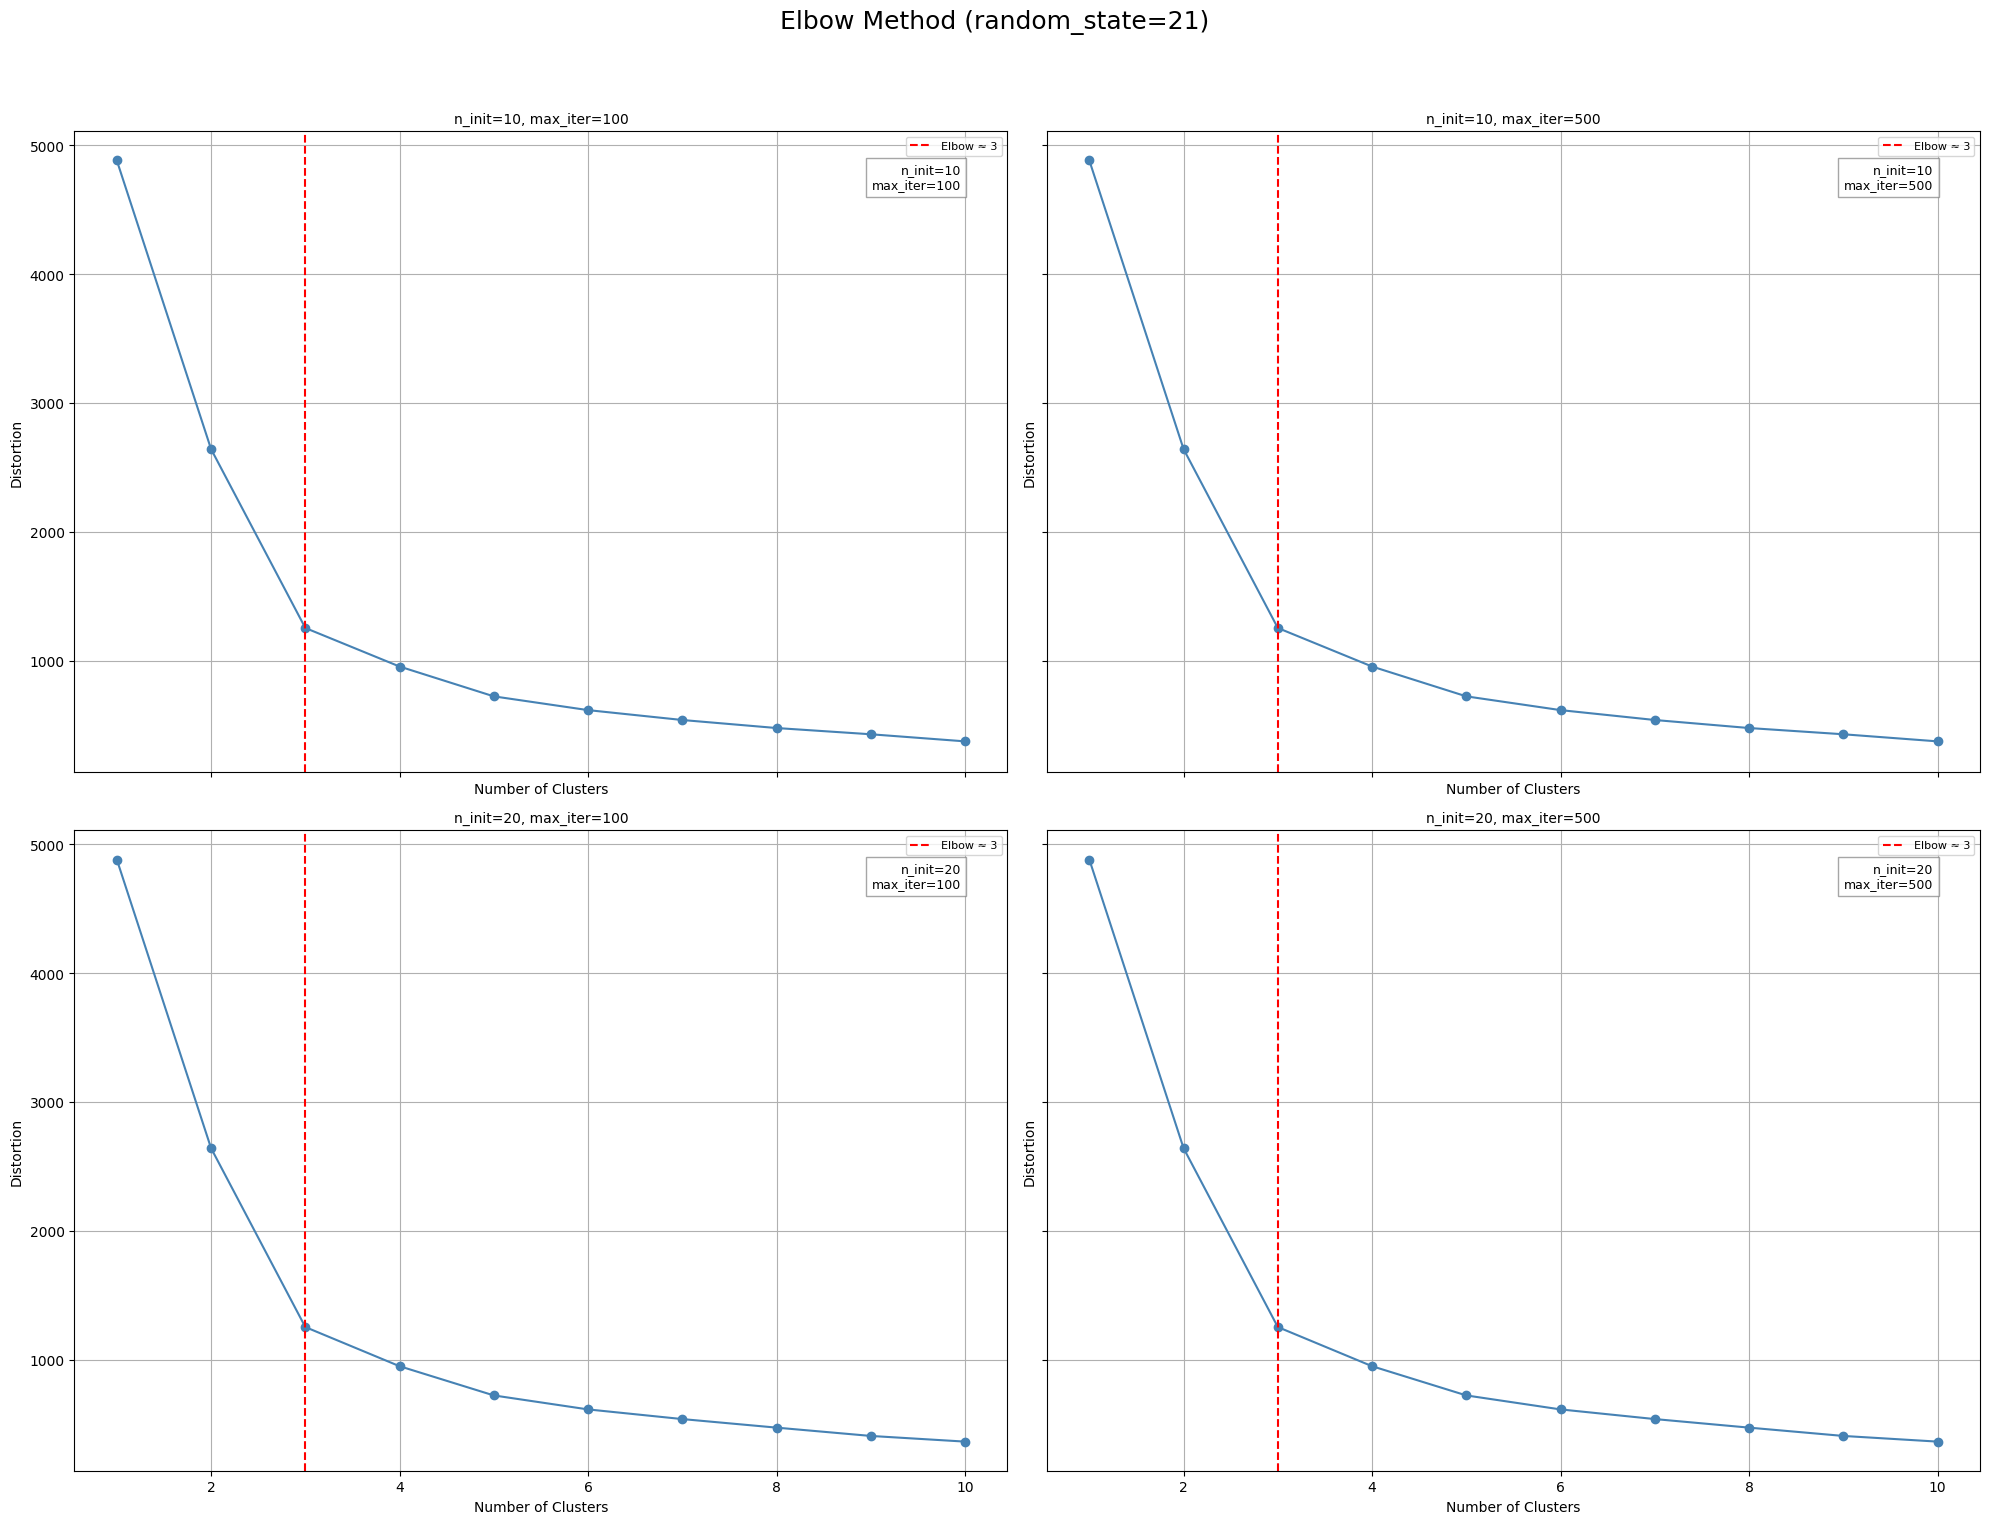


Running elbow plots for random_state=42


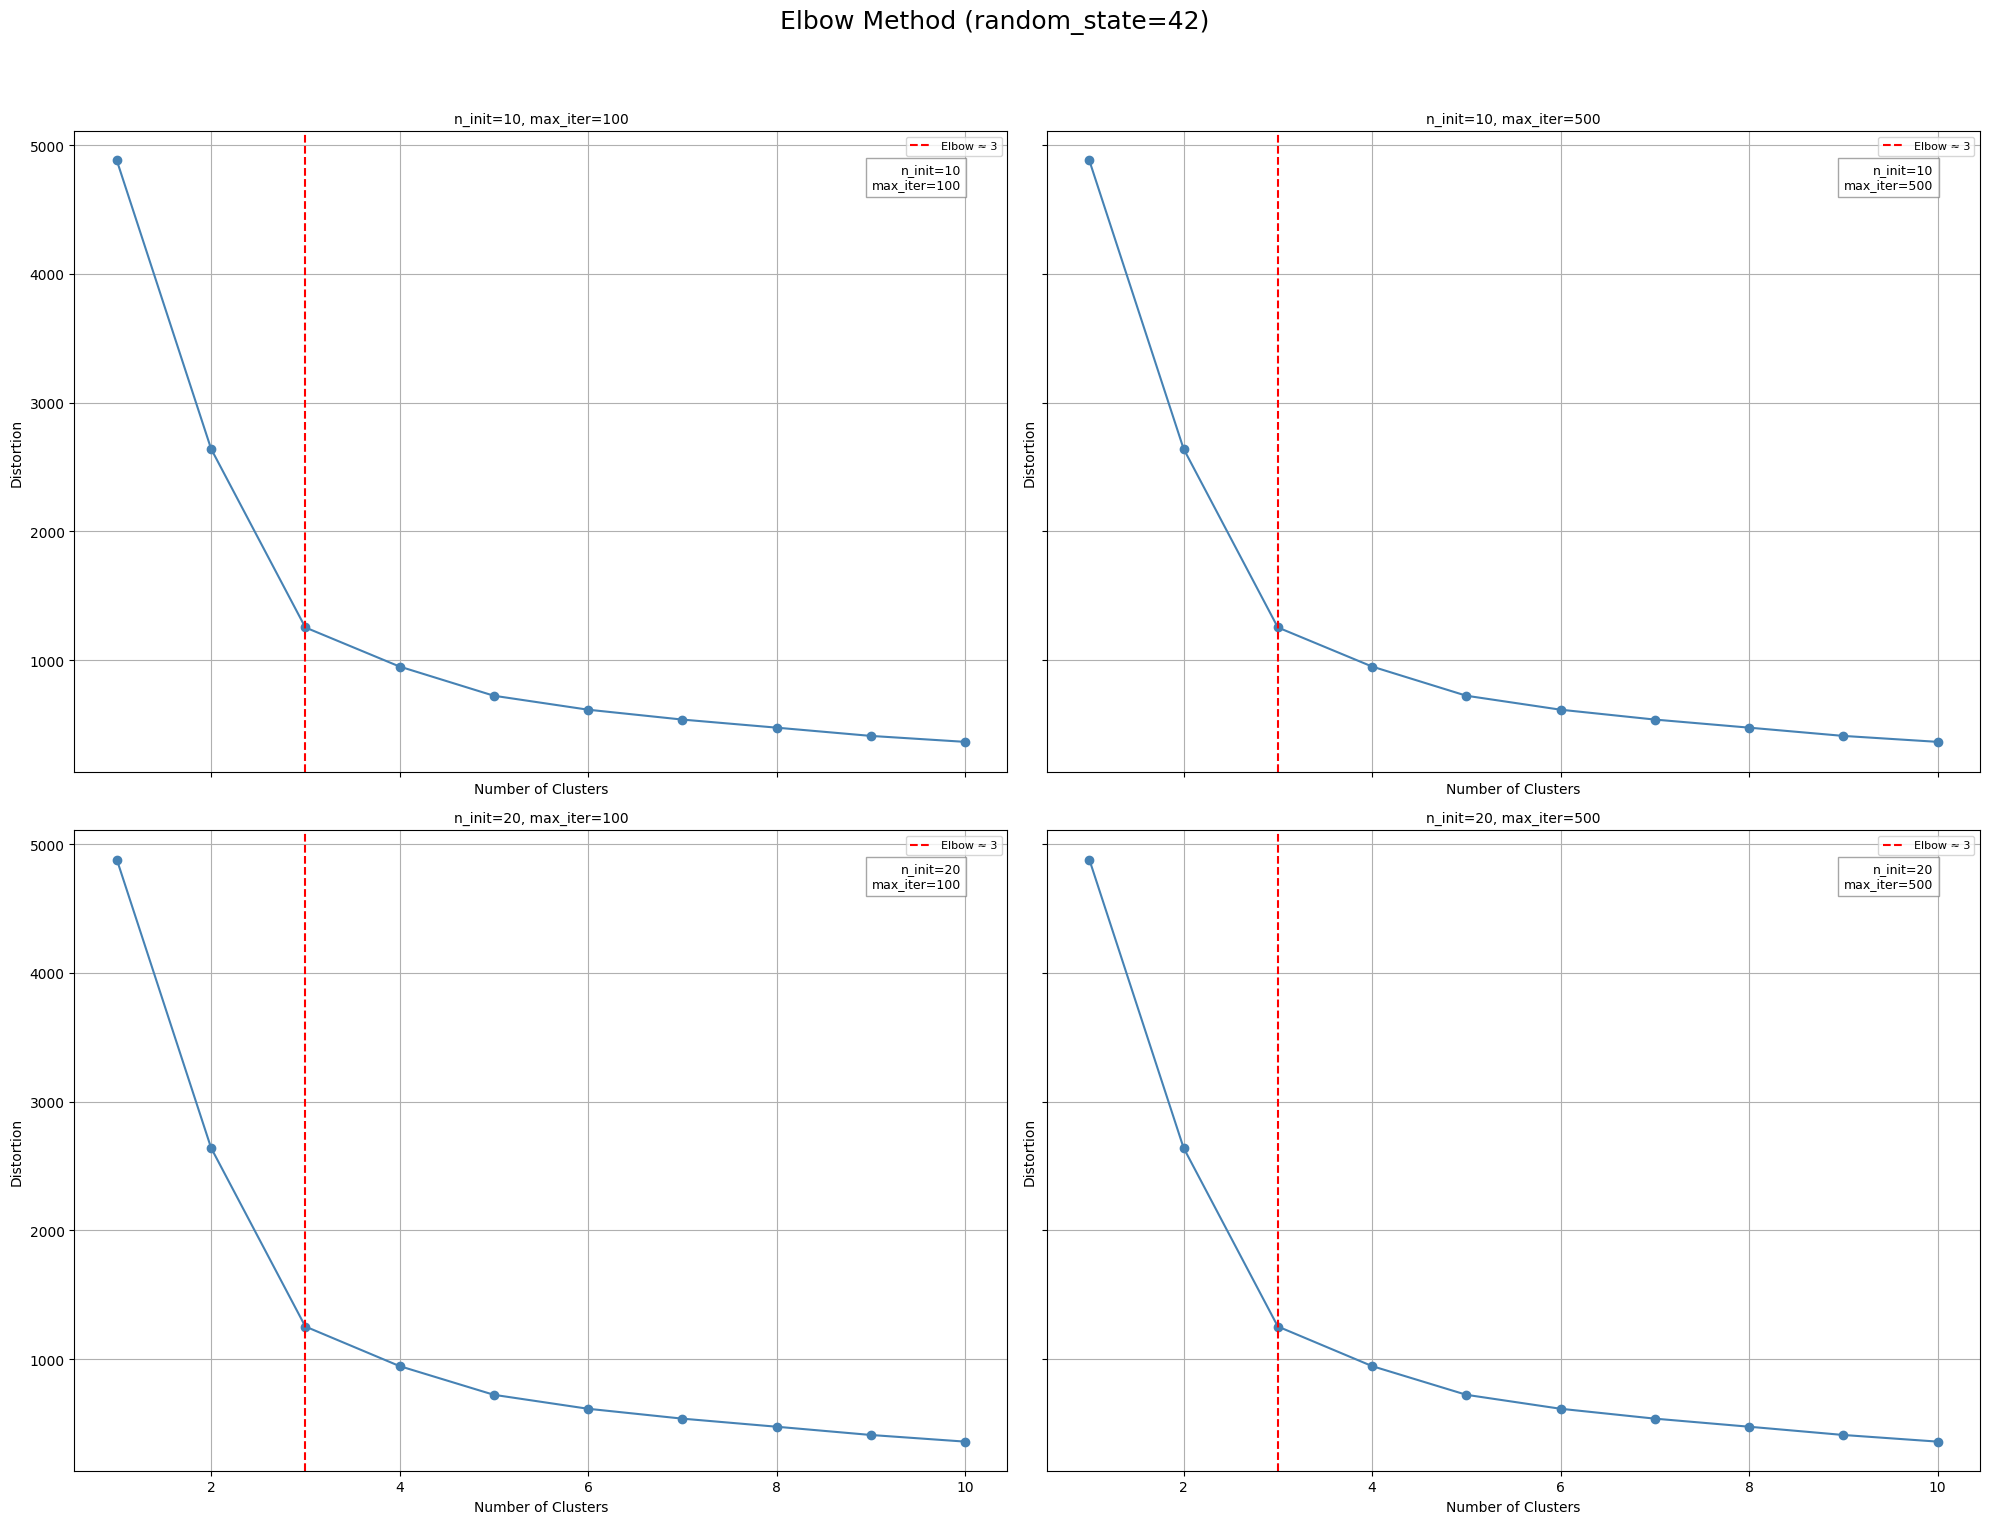


Total execution time: 9.14 seconds


In [58]:
# Start timer
start_time = time.time()

# Iterate over random states
for rs in random_states:
    print(f"\nRunning elbow plots for random_state={rs}")

    # Create figure grid
    fig, axes = plt.subplots(len(n_init_list), len(max_iter_list), figsize=(20, 16), sharex=True, sharey=True)
    fig.suptitle(f'Elbow Method (random_state={rs})', fontsize=18)

    # Iterate over parameter combinations
    for i, n_init in enumerate(n_init_list):
        for j, max_iter in enumerate(max_iter_list):
            distortions = []
            for k in n_clusters_range:
                km = KMeans(
                    n_clusters=k,
                    init='k-means++',
                    n_init=n_init,
                    max_iter=max_iter,
                    random_state=rs
                )
                km.fit(cluster_input)
                distortions.append(km.inertia_)

            # Compute second derivative to find elbow
            second_derivative = np.diff(distortions, n=2)
            elbow_point = np.argmax(second_derivative) + 2  # +2 to align with cluster count

            # Plot
            ax = axes[i, j]
            ax.plot(n_clusters_range, distortions, marker='o', linestyle='-', color='steelblue')
            ax.axvline(x=elbow_point, color='red', linestyle='--', label=f'Elbow ≈ {elbow_point}')
            ax.set_title(f'n_init={n_init}, max_iter={max_iter}', fontsize=10)
            ax.set_xlabel('Number of Clusters')
            ax.set_ylabel('Distortion')
            ax.grid(True)
            ax.legend(loc='upper right', fontsize=8)

            # Annotate parameters inside plot
            ax.text(
                0.95, 0.95,
                f'n_init={n_init}\nmax_iter={max_iter}',
                transform=ax.transAxes,
                fontsize=9,
                verticalalignment='top',
                horizontalalignment='right',
                bbox=dict(facecolor='white', alpha=0.7, edgecolor='gray')
            )

    # Final layout and display
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# End timer
end_time = time.time()
print(f"\nTotal execution time: {end_time - start_time:.2f} seconds")

KMeans algorithm:
- n_clusters: Specifies the number of clusters to form. It directly determines the granularity of the grouping.
- init: Defines the method for initializing centroids. 'k-means++' is preferred for better convergence.
- n_init: Sets how many times the algorithm runs with different centroid seeds. Higher values improve robustness.
- max_iter: Limits the number of iterations per run. Controls convergence depth.
- tol: Sets the tolerance for declaring convergence. Affects when the algorithm stops based on centroid movement.
- random_state: Fixes the seed for reproducibility. Ensures consistent results across runs.
- algorithm: Chooses the internal algorithm variant ('lloyd' or 'elkan'). 'elkan' is faster for well-separated clusters.


#### Quantifying the quality of clustering via silhouette plots

The previous code was a nonsense since each iteration found the same elbow, so we will see if each iteration with a different hyperparameter results in a cluster with different members.

The code for each model will be as follows:
- cx = where c corresponds to 'clusters' and x corresponds to the number of clusters used
- nix = where ni corresponds to 'n_init' and x to the number of initializations used
- maxix = where maxi corresponds to 'max_iter' and x to the number of maximum iterations selected

In [59]:
from sklearn.metrics import silhouette_samples

In [60]:
from matplotlib import cm

In [61]:
def plot_silhouette(kmeans_model, X):
    """
    Generates a silhouette plot to evaluate the quality of KMeans clustering.

    Parameters:
    - kmeans_model: a fitted KMeans model.
    - X: the input feature matrix used for clustering.

    Returns:
    - silhouette_avg: the average silhouette coefficient across all samples.
    """
    labels = kmeans_model.labels_
    n_clusters = len(np.unique(labels))
    silhouette_vals = silhouette_samples(X, labels, metric='euclidean')
    silhouette_avg = np.mean(silhouette_vals)

    y_ax_lower, yticks = 0, []

    for i in range(n_clusters):
        cluster_vals = silhouette_vals[labels == i]
        cluster_vals.sort()
        y_ax_upper = y_ax_lower + len(cluster_vals)

        color = cm.jet(float(i) / n_clusters)
        plt.barh(
            range(y_ax_lower, y_ax_upper),
            cluster_vals,
            height=1.0,
            edgecolor='none',
            color=color
        )

        yticks.append((y_ax_lower + y_ax_upper) / 2.)
        y_ax_lower = y_ax_upper

    plt.axvline(silhouette_avg, color="red", linestyle="--", label=f"Average: {silhouette_avg:.2f}")
    plt.yticks(yticks, [f'Cluster {i+1}' for i in range(n_clusters)])
    plt.ylabel('Cluster')
    plt.xlabel('Silhouette coefficient')
    plt.title('Silhouette plot by cluster')
    plt.legend()
    plt.tight_layout()
    plt.show()

    return silhouette_avg

In [62]:
km_c3_ni20_maxi500 = KMeans(n_clusters=3,
            init='k-means++',
            n_init=20,
            max_iter=500,
            random_state=42)

In [63]:
ym_c3_ni20_maxi500 = km_c3_ni20_maxi500.fit(cluster_input)

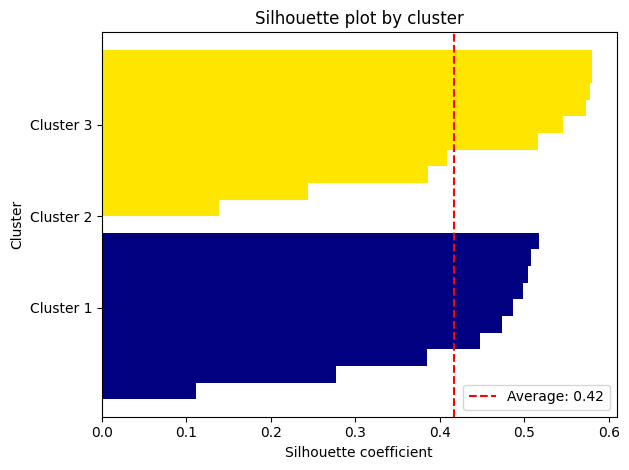

In [69]:
silhoutte_c3_ni20_maxi500 = plot_silhouette(ym_c3_ni20_maxi500, cluster_input)

In [73]:
np.bincount(ym_c3_ni20_maxi500.labels_)

array([10,  1, 10])

In [65]:
km_c3_ni10_maxi100 = KMeans(n_clusters=3,
            init='k-means++',
            n_init=10,
            max_iter=100,
            random_state=42)

In [66]:
ym_c3_ni10_maxi100 = km_c3_ni10_maxi100.fit(cluster_input)

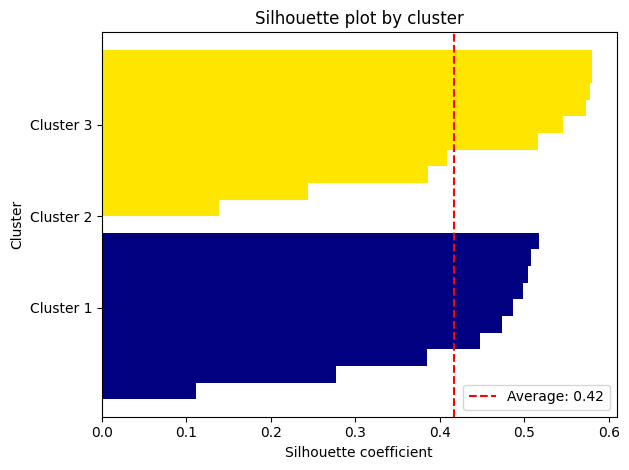

In [68]:
silhoutte_c3_ni10_maxi100 = plot_silhouette(ym_c3_ni10_maxi100, cluster_input)

In [72]:
np.bincount(ym_c3_ni10_maxi100.labels_)

array([10,  1, 10])

In [74]:
c3_ni10_maxi100 = df_final_win_country_delete.copy()

In [75]:
c3_ni10_maxi100['cluster'] = ym_c3_ni10_maxi100.labels_

In [76]:
c3_ni20_maxi500 = df_final_win_country_delete.copy()

In [77]:
c3_ni20_maxi500['cluster'] = ym_c3_ni20_maxi500.labels_

In [78]:
import country_converter as coco

In [79]:
c3_ni10_maxi100['ISO_A3'] = coco.convert(names=c3_ni10_maxi100['Country'], to='ISO3')
c3_ni20_maxi500['ISO_A3'] = coco.convert(names=c3_ni20_maxi500['Country'], to='ISO3')

In [80]:
clusters_c3_ni10_maxi100 = c3_ni10_maxi100[['Country', 'ISO_A3', 'cluster']].copy()
clusters_c3_ni20_maxi500 = c3_ni20_maxi500[['Country', 'ISO_A3', 'cluster']].copy()

In [81]:
clusters_c3_ni10_maxi100.loc[:, 'Continent'] = coco.convert(
    names=clusters_c3_ni10_maxi100['Country'], to='continent'
)

clusters_c3_ni20_maxi500.loc[:, 'Continent'] = coco.convert(
    names=clusters_c3_ni20_maxi500['Country'], to='continent'
)

In [82]:
def print_cluster_groups(df_clusters):
    """
    Groups countries by their cluster and prints each group with country name and continent.

    Parameters:
    - df_clusters: DataFrame containing 'Country', 'cluster', and 'CONTINENT' columns
    """

    # Ensure required columns exist
    required_cols = {'Country', 'cluster', 'Continent'}
    if not required_cols.issubset(df_clusters.columns):
        print("Missing required columns in the DataFrame.")
        return

    # Group countries by cluster
    grouped = df_clusters.groupby('cluster')

    # Print each cluster group
    for cluster_id, group in grouped:
        print(f"\n🌍 Cluster {cluster_id} ({len(group)} countries):")
        for _, row in group.iterrows():
            country = row['Country']
            continent = row['Continent']
            print(f" - {country} ({continent})")

In [83]:
print_cluster_groups(clusters_c3_ni10_maxi100)


🌍 Cluster 0 (10 countries):
 - Czech (Europe)
 - France (Europe)
 - Germany (Europe)
 - Italy (Europe)
 - Netherlands (Europe)
 - Norway (Europe)
 - Spain (Europe)
 - Sweden (Europe)
 - Thailand (Asia)
 - United Kingdom (Europe)

🌍 Cluster 1 (1 countries):
 - Paraguay (America)

🌍 Cluster 2 (10 countries):
 - Austria (Europe)
 - Belgium (Europe)
 - Croatia (Europe)
 - Estonia (Europe)
 - Finland (Europe)
 - Latvia (Europe)
 - Lithuania (Europe)
 - Luxembourg (Europe)
 - Portugal (Europe)
 - Slovenia (Europe)


In [84]:
print_cluster_groups(clusters_c3_ni20_maxi500)


🌍 Cluster 0 (10 countries):
 - Czech (Europe)
 - France (Europe)
 - Germany (Europe)
 - Italy (Europe)
 - Netherlands (Europe)
 - Norway (Europe)
 - Spain (Europe)
 - Sweden (Europe)
 - Thailand (Asia)
 - United Kingdom (Europe)

🌍 Cluster 1 (1 countries):
 - Paraguay (America)

🌍 Cluster 2 (10 countries):
 - Austria (Europe)
 - Belgium (Europe)
 - Croatia (Europe)
 - Estonia (Europe)
 - Finland (Europe)
 - Latvia (Europe)
 - Lithuania (Europe)
 - Luxembourg (Europe)
 - Portugal (Europe)
 - Slovenia (Europe)


In [85]:
print_cluster_groups(clusters_c3_ni10_maxi100)


🌍 Cluster 0 (10 countries):
 - Czech (Europe)
 - France (Europe)
 - Germany (Europe)
 - Italy (Europe)
 - Netherlands (Europe)
 - Norway (Europe)
 - Spain (Europe)
 - Sweden (Europe)
 - Thailand (Asia)
 - United Kingdom (Europe)

🌍 Cluster 1 (1 countries):
 - Paraguay (America)

🌍 Cluster 2 (10 countries):
 - Austria (Europe)
 - Belgium (Europe)
 - Croatia (Europe)
 - Estonia (Europe)
 - Finland (Europe)
 - Latvia (Europe)
 - Lithuania (Europe)
 - Luxembourg (Europe)
 - Portugal (Europe)
 - Slovenia (Europe)


* Not work we need to group Paraguay into a cluster